In [13]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as ss
import warnings
from IPython.display import clear_output

warnings.filterwarnings('ignore')
sp.init_printing()

In [14]:
pl1, pl2, tp1, tp2, tl1, tl2, dl1, dl2 = sp.symbols('p_1 p_2 theta_P^1 theta_P^2 theta_L^1 theta_L^2 delta_L^1 delta_L^2')

In [15]:
# Define the matrix elements
P1 = (1/2) * sp.Matrix([
    [1,                  sp.cos(2*tp1),               sp.sin(2*tp1),                  0],
    [sp.cos(2*tp1),    sp.cos(2*tp1)**2,            sp.sin(2*tp1)*sp.cos(2*tp1),  0],
    [sp.sin(2*tp1),    sp.sin(2*tp1)*sp.cos(2*tp1), sp.sin(2*tp1)**2,             0],
    [0,                  0,                             0,                                0]
])

P2 = (1/2) * sp.Matrix([
    [1,                  sp.cos(2*tp2),               sp.sin(2*tp2),                  0],
    [sp.cos(2*tp2),    sp.cos(2*tp2)**2,            sp.sin(2*tp2)*sp.cos(2*tp2),  0],
    [sp.sin(2*tp2),    sp.sin(2*tp2)*sp.cos(2*tp2), sp.sin(2*tp2)**2,             0],
    [0,                  0,                             0,                                0]
])


# Define the matrix
LR1 = pl1**2 * sp.Matrix([
    [1, 0,                                            0,                                             0],
    [0, sp.cos(2*tl1)**2 + sp.cos(dl1)*sp.sin(2*tl1)**2, (1 - sp.cos(dl1)) * sp.sin(2*tl1) * sp.cos(2*tl1), -sp.sin(dl1)*sp.sin(2*tl1)],
    [0, (1 - sp.cos(dl1)) * sp.sin(2*tl1) * sp.cos(2*tl1), sp.sin(2*tl1)**2 + sp.cos(dl1)*sp.cos(2*tl1)**2, sp.sin(dl1)*sp.cos(2*tl1)],
    [0, sp.sin(dl1)*sp.sin(2*tl1),                -sp.sin(dl1)*sp.cos(2*tl1),                   sp.cos(dl1)]
])

LR2 = pl2**2 * sp.Matrix([
    [1, 0,                                            0,                                             0],
    [0, sp.cos(2*tl2)**2 + sp.cos(dl2)*sp.sin(2*tl2)**2, (1 - sp.cos(dl2)) * sp.sin(2*tl2) * sp.cos(2*tl2), -sp.sin(dl2)*sp.sin(2*tl2)],
    [0, (1 - sp.cos(dl2)) * sp.sin(2*tl2) * sp.cos(2*tl2), sp.sin(2*tl2)**2 + sp.cos(dl2)*sp.cos(2*tl2)**2, sp.sin(dl2)*sp.cos(2*tl2)],
    [0, sp.sin(dl2)*sp.sin(2*tl2),                -sp.sin(dl2)*sp.cos(2*tl2),                   sp.cos(dl2)]
])



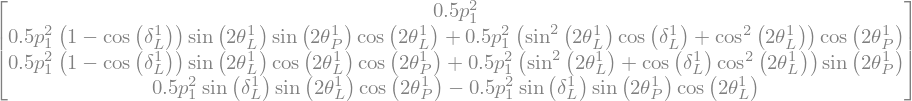

In [18]:
S0 = sp.Matrix([1, 0, 0, 0])
Si = LR1 @ P1 @ S0
Si_num = Si.subs(dl1, np.pi/2).subs(pl1, 1).evalf()
Si

In [8]:
tin = sp.symbols('\\theta_{in}')
#Si = sp.Matrix([1, sp.cos(2*tin) * sp.cos(dg), sp.sin(2*tin) * sp.cos(dg), sp.sin(dg)])
#Si

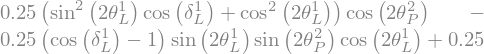

In [24]:
So = LR2 @ P2 @ Si
expr = So.subs(pl2, 1)[0]
#f = sp.lambdify((tin, tp2, dg), expr)
So[0].subs(pl1, 1).subs(pl2, 1).subs(tp1, 0).simplify()

In [7]:
import matplotlib.pyplot as plt

dg_num = np.pi/4
tin_num = np.pi/6
tp2_num = np.linspace(0, np.pi, 1000)

plt.plot(tp2_num, f(dg_num, tp2_num, dg_num))


NameError: name 'f' is not defined

In [ ]:

W_NATURE = np.random.random(size=2) * 2 - 1
SIGMA = 0.05
COVARIANCE = np.eye(len(W_NATURE))

##### 
# Gaussian process functions
##### 


def model(X: np.ndarray, w: np.ndarray = W_NATURE):
    """
    Model function that computes the output based on input x and weights w.
    """
    print(X.shape, w.shape)
    return X.T @ w 


def measure(X: np.ndarray, w: np.ndarray = W_NATURE, sigma: float = SIGMA, model: callable = model):
    """
    Measure function that computes the output based on input x and weights w,
    adding Gaussian noise.
    """
    if len(X) > 0:
        return model(X, w) + ss.multivariate_normal.rvs(
            mean=np.zeros(X.shape[1]), cov=SIGMA**2 * np.identity(X.shape[1])
        )
    return np.array([])


def generate_1dX_poly(x: np.ndarray, order: int = 2):
    """
    Generate a 1D input array for the model.
    """
    if len(x) == 0:
        return np.array([])
    vectors = [x**i for i in range(order)]
    return np.hstack(vectors).T


def generate_1dX_stokes(x: np.ndarray):
    """
    Generate a 1D input array for the model.
    """
    if len(x) == 0:
        return np.array([])
    vectors = [[np.sin(2*xi**2), np.cos(2*xi**2)] for xi in x]
    return np.hstack(vectors)


def generate_1dX_sin(x: np.ndarray, order: int = 2):
    """
    Generate a 1D input array for the model.
    """
    if len(x) == 0:
        return np.array([])
    vectors = [np.sin(i * 2 * np.pi * x) for i in range(order)]
    return np.hstack(vectors).T


def calc_A(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Calculate matrix A
    """
    if len(X) == 0:
        return np.linalg.inv(cov)
    return sigma ** (-2) * X @ X.T + np.linalg.inv(cov)


def get_posterior_dist(
    X: np.ndarray,
    y: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the posterior distribution of weights w given measurements D={X, y}.
    """
    if len(y) == 0:
        return ss.multivariate_normal(mean=np.zeros(cov.shape[0]), cov=cov)

    assert len(y) == X.shape[1], f"X.shape[1] = {X.shape[1]} != y.shape[0] = {len(y)}"

    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    m = A_inv @ X @ y / sigma**2
    return ss.multivariate_normal(mean=m, cov=A_inv)


def get_pfstar_mean(
    xstar: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the mean prediction of the model at xstar.
    """
    if len(X) == 0:
        return np.repeat(0, xstar.shape[1])
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    vec = A_inv @ X @ y
    return np.dot(xstar.T, vec) / sigma**2



def get_pfstar_var(
    xstar: np.ndarray,
    X: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the variance of the prediction at xstar.
    """
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)

    # Ensure xstar is 2D
    if xstar.ndim == 1:
        xstar = xstar.reshape(1, -1)

    results = np.einsum("ni,ij,jn->n", xstar.T, A_inv, xstar)

    return results


def get_pfstar_dist(
    xstar: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the posterior distribution of weights w given measurements y and a new input xstar.
    """
    m = get_pfstar_mean(xstar, X, y, cov, sigma)
    var = get_pfstar_var(xstar, X, y, cov, sigma)
    return ss.norm(loc=m, scale=var)



In [11]:
######
# Plotting functions
######

def plot_measurements(
    ax: plt.Axes,
):
    pass

def plot_contour2d(
        ax: plt.Axes,
        dist: ss.rv_continuous,
        color: str = "black",
):
    """
    Plot the prior distribution.
    """
    w0, w1 = np.mgrid[-2:2:0.01, -2:2:0.01]
    pos = np.dstack((w0, w1))
    return ax.contour(w0, w1, dist.pdf(pos), levels=2, colors=color)

def plot_prediction(
        ax: plt.Axes,
        X: np.ndarray,
        y: np.ndarray,
        cov: np.ndarray = COVARIANCE,
        sigma: float = SIGMA,
        w: np.ndarray = W_NATURE,
):
    """
    Plot the uncertainty of the model.
    """
    xstar = np.linspace(0, 2*np.pi, 100).reshape(-1, 1)
    xstar = generate_1dX_stokes(xstar, order=len(w))
    ystar = get_pfstar_mean(xstar, X, y, cov=cov, sigma=sigma)
    var = get_pfstar_var(xstar, X, cov=cov, sigma=sigma)
    std = np.sqrt(var)
    x = xstar[1, :]
    ax.plot(x, ystar, color="blue", label="Mean")
    ax.fill_between(
        x,
        ystar - std,
        ystar + std,
        alpha=0.2,
        color="blue",
        label="Confidence Interval",
    )

def plot_variance(
        ax: plt.Axes,
        X: np.ndarray,
        y: np.ndarray,
        cov: np.ndarray = COVARIANCE,
        w: np.ndarray = W_NATURE,
):
    """
    Plot the uncertainty of the model.
    """
    xstar = np.linspace(0, 2*np.pi, 100).reshape(-1, 1)
    xstar = generate_1dX(xstar, order=len(w))
    var = get_pfstar_var(xstar, X, cov=cov, sigma=SIGMA)
    std = np.sqrt(var)
    x = xstar[1, :]
    ax.plot(x, std, color="blue", label="Standard deviation")
    ax.set_ylim([0, None])
    ax.axvline(x[np.argmax(var)], color="k", linestyle="dashed", label=f"best x={x[np.argmax(var)]:.2g}")
    new_x = gp_suggest(X, cov=COVARIANCE, sigma=SIGMA)
    ax.axvline(new_x, color="gray", linestyle="dashed", label=f"best new_x={new_x:.2g}")

def plot_real_space(
        ax: plt.Axes,
        X: np.ndarray,
        y: np.ndarray,
        w: np.ndarray = W_NATURE,
):
    xm = generate_1dX(np.linspace(0, 1, 1000).reshape(-1, 1), order=len(w))
    means = get_pfstar_mean(xm, X, y)
    vars = get_pfstar_var(xm, X)

    ax.plot(xm[1, :], means, label="mean", color="blue")
    ax.fill_between(
        xm[1, :],
        y1=means - np.sqrt(vars),
        y2=means + np.sqrt(vars),
        label="$\pm \sigma$",
        color="blue",
        alpha=0.2,
    )


def plot_nature(
        ax: plt.Axes,
        model: callable,
        x_generator: callable = generate_1dX,
        w: np.ndarray = W_NATURE,
):
    """
    Plot the nature function.
    """
    x = np.linspace(0, 1, 100)
    X = x_generator(x.reshape(-1, 1), order=len(w))
    y = model(X, w=w)
    ax.plot(x, y, label="Nature", color="black", linestyle="--")



NameError: name 'generate_1dX' is not defined

In [12]:

######
# SmartExp functions
######

def update_data(x: np.ndarray, X, y, x_generator: callable = generate_1dX, w: np.ndarray = W_NATURE, sigma: float = SIGMA):
    """
    Update the data with new measurements.
    """
    X_new = x_generator(x.reshape(-1, 1), order=len(w))
    y_new = measure(X_new, w=w, sigma=sigma)
    if len(X) == 0:
        return X_new, y_new
    X = np.hstack((X, X_new))
    y = np.hstack((y, y_new))
    return X, y

def gp_suggest(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    xstar = generate_1dX(np.linspace(0, 1, 100).reshape(-1, 1), order=cov.shape[0])
    x = xstar[1, :]
    var = get_pfstar_var(xstar, X, cov=COVARIANCE, sigma=SIGMA)
    #xstar = xstar[1, np.argmax(var)] # conviene calcular los autovectores de la matriz 
    return x[np.argmax(var)]

def gp_explore_suggest(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA, l: float = 1):
    xstar = generate_1dX(np.linspace(0, 1, 100).reshape(-1, 1), order=cov.shape[0])
    var = get_pfstar_var(xstar, X, cov=COVARIANCE, sigma=SIGMA) 
    if len(X) > 0:
        xm = X[1, :]
        dist = 0
        for xi in xm:
            dist += np.exp(- np.linalg.norm(xi - xstar[1, :]) / l**2)
    else:
        dist = np.zeros_like(var)
    xstar = xstar[1, np.argmax(var + dist)] # conviene calcular los autovectores de la matriz 
    return np.array([xstar])

def random_suggest():
    """
    Randomly suggest a new point.
    """
    return np.random.random(size=1)

def grid_suggest(X: np.ndarray, size: int = 10):
    """
    Suggest a new point based on a grid search.
    """
    xstar = np.linspace(0, 1, size).reshape(-1, 1)
    if len(X) > 0:
        xstar = np.linspace(0, 1, size)[len(X[1,:])]
    else:
        xstar = 0
    return np.array([xstar])

NameError: name 'generate_1dX' is not defined

(2, 100) (2,)


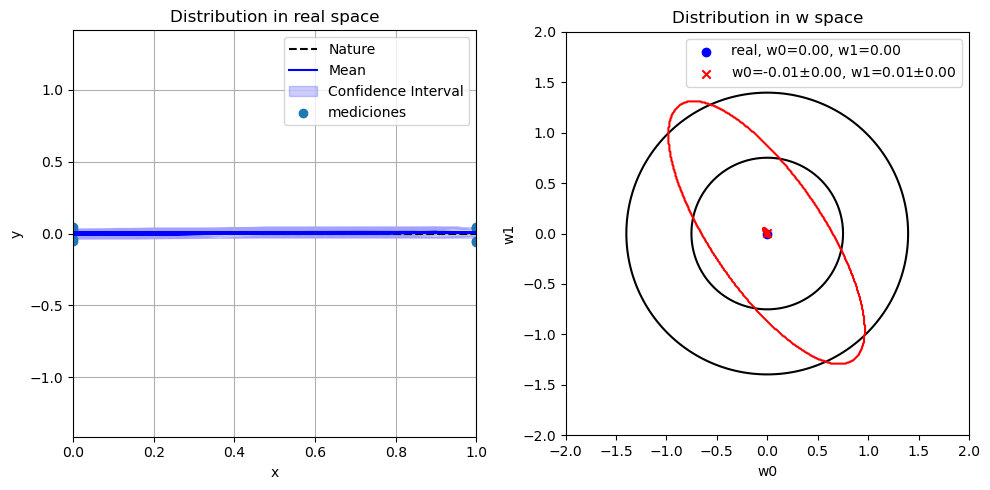

(2, 1) (2,)


In [106]:

#W_NATURE = np.random.random(size=2) * 2 - 1
tin_nature = np.pi/6
dg_nature = np.pi/2
W_NATURE = np.array([np.sin(2*tin_nature) * np.cos(dg_nature) / 2, np.cos(2 * tin_nature) * np.cos(dg_nature) / 2])
SIGMA = 0.05
COVARIANCE = np.eye(len(W_NATURE))

X = np.array([]).reshape(-1, 1)
y = np.array([])
reps = 10
for i in range(reps):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    # Plot prior
    prior = ss.multivariate_normal(mean=np.zeros(len(W_NATURE)), cov=COVARIANCE)
    plot_contour2d(ax2, prior)

    # Plot real value of the parameters
    ax2.scatter(
        W_NATURE[0],
        W_NATURE[1],
        label=f"real, w0={W_NATURE[0]:.2f}, w1={W_NATURE[1]:.2f}",
        color="blue",
        marker="o",
    )
    plot_nature(ax1, model, w=W_NATURE, x_generator=generate_1dX_stokes)

    if len(X) > 0:
        # Compute posterior given measurements and plot
        posterior = get_posterior_dist(X, y)
        plot_contour2d(ax2, posterior, color="red")

        # Plot best prediction in w space
        ax2.scatter(
            posterior.mean[0],
            posterior.mean[1],
            label=f"w0={posterior.mean[0]:.2f}$\pm${posterior.cov[0][0]:.2f}, w1={posterior.mean[1]:.2f}$\pm${posterior.cov[1][1]:.2f}",
            color="red",
            marker="x",
        )
    
    # Plot the model's prediction
    plot_prediction(ax1, X, y, cov=COVARIANCE, w=W_NATURE)
    
    
    # Plot measurements
    if len(X) > 0:
        ax1.scatter(X[1], y, label="mediciones")
    
    
    ax1.set_title("Distribution in real space")
    ax1.set_ylabel("y")
    ax1.set_xlabel("x")
    ax1.set_ylim([-np.sqrt(2), np.sqrt(2)])
    ax1.set_xlim([-0, 1])
    ax1.legend()
    
    ax2.set_ylabel("w1")
    ax2.set_xlabel("w0")
    ax2.set_title("Distribution in w space")
    ax2.set_xlim(-2, 2)
    ax2.set_ylim(-2, 2)
    ax2.set_aspect("equal")
    
    ax1.grid()
    ax2.legend()
    plt.tight_layout()
    fig.show()
    plt.show()
    
    new_x = gp_suggest(X, cov=COVARIANCE, sigma=SIGMA)
    #new_x = random_suggest()
    #new_x = grid_suggest(X, size=reps)
    X, y = update_data(new_x, X, y, w=W_NATURE, sigma=SIGMA, x_generator=generate_1dX)

    #time.sleep(2)
    input()
    clear_output(wait=True)